# Exponent- en mantissatruncatie op dezelfde MX-checkpoints

Deze notebook analyseert uitsluitend de opgeslagen **post-hocevaluatie**. De twee vaste checkpoints zijn **epoch 100** en het tijdens de directe gezamenlijke training gekozen **E4M3-bestcheckpoint**. Voor beide gebruiken alle acht routes hetzelfde checkpoint en dezelfde testbeelden.

De directe E4M3-, E2M3- en E2M1-exports vormen de controles. Mantissatruncatie wordt opnieuw getest vanuit E2M3; exponenttruncatie vertrekt vanuit E4M3. De gecombineerde route verwijdert eerst exponentbits en daarna mantissabits. Alle afleidingen behouden hun bronschaal, met A32 en de reeds getrainde **BN-bank van de doelprecisie**. Er is geen training, nieuwe checkpointselectie, BN-herkalibratie of schaalcorrectie.


In [1]:
from pathlib import Path
RUN_DIR = Path('C:\\Users\\renzo\\master-thesis-mx\\mx_runs\\mx_triple_posthoc_truncation_eval\\20261023_173343_934141_evaluate')
SAVE_FIGURES = True  # Nieuwe analysemap; ruwe resultaten blijven behouden.


In [2]:
import importlib.util
import sys
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

helper_path = (RUN_DIR / "notebook_support.py").resolve()
spec = importlib.util.spec_from_file_location("mx_triple_posthoc_analysis", helper_path)
analysis = importlib.util.module_from_spec(spec)
sys.modules[spec.name] = analysis
spec.loader.exec_module(analysis)
run = analysis.load_run(RUN_DIR, verify_per_image=True)
figures = {}
display(Markdown(analysis.status_markdown(run)))
display(analysis.diagnostics_table(run))


**Post-hocevaluatie bevestigd.** Beide vaste checkpointrollen en alle acht routes zijn gecontroleerd.

Deze notebook leest opgeslagen rapporten en per-beeldarrays. Zij voert geen training, modelevaluatie of BN-herkalibratie uit. De selectie blijft epoch 100 en het eerder gekozen E4M3-bestcheckpoint; er wordt geen nieuw bestcheckpoint gezocht.

,Niveau,Melding
0,RUNWAARSCHUWING,The argument 'device' of Tensor.pin_memory() i...
1,RUNWAARSCHUWING,The argument 'device' of Tensor.is_pinned() is...


## 1. Acht evaluatieroutes, drie doelprecisies

De routes zijn **geen acht zelfstandig getrainde precisies**. De drie directe controles zijn de tijdens training gebruikte gewichtsmodi. De overige routes vervangen uitsluitend hun MX-gewichtsrepresentatie tijdens inferentie.

Voor mantissatruncatie: `[s ee mmm] → [s ee m]`, dus de twee laagste mantissabits worden verwijderd. Voor exponenttruncatie: `[s e3 e2 e1 e0 mmm] → [s e3 e2 mmm]`; teken en mantissa blijven behouden en de twee hoogste exponentbits worden opnieuw als E2-exponentveld geïnterpreteerd. Dit is geen exponentrebiasing. De gecombineerde route past beide bewerkingen achtereenvolgens toe.

De twee afrondingsroutes zijn controles vanuit opgeslagen bronelementen. **Afronden E4M3 → E2M3 houdt ook de E4M3-bronschaal vast** en kan daarom sterk satureren. Het is geen nieuwe directe MX-kwantisatie met een aangepast schaalbereik.


In [3]:
display(analysis.route_table())


,Route,Beschrijving,Doelbits,A,BN-bank,Bewerking,Schaal,Directe vergelijking
0,direct8,Direct E4M3,8,32,8,Direct uit FP32 G(W),Eigen directe E4M3-schaal,direct8
1,direct6,Direct E2M3,6,32,32,Direct uit FP32 G(W),Eigen directe E2M3-schaal,direct6
2,direct4,Direct E2M1,4,32,4,Direct uit FP32 G(W),Eigen directe E2M1-schaal,direct4
3,round64,Afronden E2M3 → E2M1,4,32,4,RNE op E2M3-elementen,E2M3-bronschaal behouden,direct4
4,mantissa64,Mantissatruncatie E2M3 → E2M1,4,32,4,Twee mantissa-LSB's verwijderen,E2M3-bronschaal behouden,direct4
5,round86,Afronden E4M3 → E2M3; E4-schaal vast,6,32,32,RNE op E4M3-elementen; saturatiecontrole,E4M3-bronschaal behouden,direct6
6,exponent86,Exponenttruncatie E4M3 → E2M3,6,32,32,Twee hoogste exponentbits behouden,E4M3-bronschaal behouden,direct6
7,combined864,Exponent + mantissa E4M3 → E2M1,4,32,4,Eerst exponent-MSB-truncatie; daarna mantissa-...,E4M3-bronschaal behouden,direct4


## 2. Accuracies op epoch 100 en het vaste E4M3-bestcheckpoint

Iedere groep gebruikt één en hetzelfde checkpoint. De drie rechtstreekse controls worden opnieuw op dezelfde beelden gemeten als de truncatieroutes. Een lage truncatieaccuracy is een mogelijke onderzoeksuitkomst en op zichzelf geen technische FAIL.


,role,epoch,path,Beschrijving,weight_bits,bn_bank_key,correct1,n,top1_percent,hard_cross_entropy
8,last_epoch,100,direct8,Direct E4M3,8,8,24694,26032,94.8602%,0.236221
9,last_epoch,100,direct6,Direct E2M3,6,32,24732,26032,95.0061%,0.200406
10,last_epoch,100,direct4,Direct E2M1,4,4,24749,26032,95.0715%,0.186246
11,last_epoch,100,round64,Afronden E2M3 → E2M1,4,4,24625,26032,94.5951%,0.198839
12,last_epoch,100,mantissa64,Mantissatruncatie E2M3 → E2M1,4,4,24571,26032,94.3877%,0.212873
13,last_epoch,100,round86,Afronden E4M3 → E2M3; E4-schaal vast,6,32,4149,26032,15.9381%,2.272554
14,last_epoch,100,exponent86,Exponenttruncatie E4M3 → E2M3,6,32,4149,26032,15.9381%,2.274756
15,last_epoch,100,combined864,Exponent + mantissa E4M3 → E2M1,4,4,4149,26032,15.9381%,2.274692
0,best_E4M3_test,54,direct8,Direct E4M3,8,8,24740,26032,95.0369%,0.214138
1,best_E4M3_test,54,direct6,Direct E2M3,6,32,24760,26032,95.1137%,0.189811


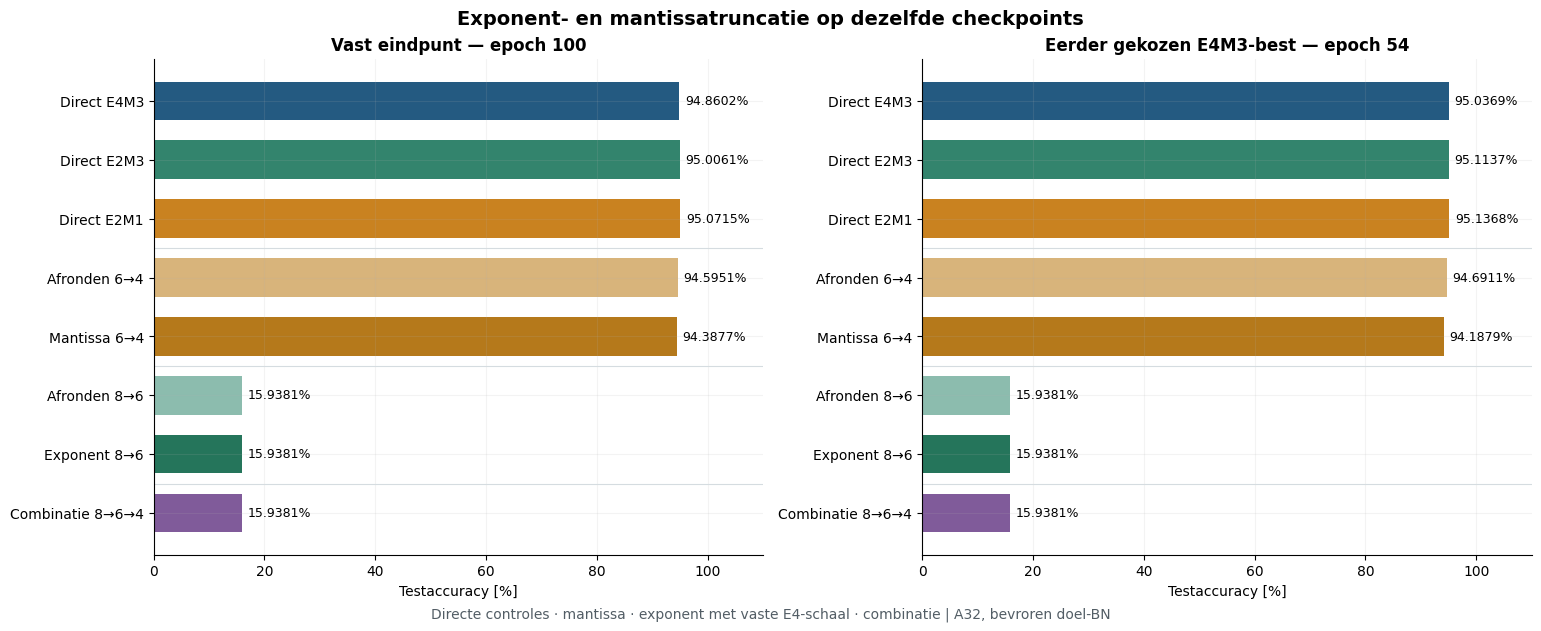

In [4]:
display(analysis.accuracy_table(run).style.format({"top1_percent": "{:.4f}%", "hard_cross_entropy": "{:.6f}"}))
figures["checkpoint_accuracy"] = analysis.plot_checkpoint_accuracy(run)
plt.show()


## 3. Verlies of winst ten opzichte van de directe doelmodus

Mantissa 6→4 en combinatie 8→6→4 worden met directe E2M1 vergeleken; exponent 8→6 met directe E2M3. Positief betekent dat de afgeleide route meer correcte voorspellingen geeft. De afrondingscontroles tonen het verschil tussen eerst een opgeslagen bron vormen en daarna afronden of trunceren.

Accuracyverschillen kunnen rekenkundig worden opgeteld, maar vormen geen onafhankelijke causale ontbinding. De ingrepen werken door een niet-lineair netwerk met vaste, eerder op directe gewichten geleerde BN-statistieken.


,role,epoch,path,Beschrijving,Directe referentie,Delta accuracy [pp],Netto correcte beelden
0,last_epoch,100,round64,Afronden E2M3 → E2M1,Direct E2M1,-0.4763,-124
1,last_epoch,100,mantissa64,Mantissatruncatie E2M3 → E2M1,Direct E2M1,-0.6838,-178
2,last_epoch,100,round86,Afronden E4M3 → E2M3; E4-schaal vast,Direct E2M3,-79.0681,-20583
3,last_epoch,100,exponent86,Exponenttruncatie E4M3 → E2M3,Direct E2M3,-79.0681,-20583
4,last_epoch,100,combined864,Exponent + mantissa E4M3 → E2M1,Direct E2M1,-79.1334,-20600
5,best_E4M3_test,54,round64,Afronden E2M3 → E2M1,Direct E2M1,-0.4456,-116
6,best_E4M3_test,54,mantissa64,Mantissatruncatie E2M3 → E2M1,Direct E2M1,-0.9488,-247
7,best_E4M3_test,54,round86,Afronden E4M3 → E2M3; E4-schaal vast,Direct E2M3,-79.1756,-20611
8,best_E4M3_test,54,exponent86,Exponenttruncatie E4M3 → E2M3,Direct E2M3,-79.1756,-20611
9,best_E4M3_test,54,combined864,Exponent + mantissa E4M3 → E2M1,Direct E2M1,-79.1987,-20617


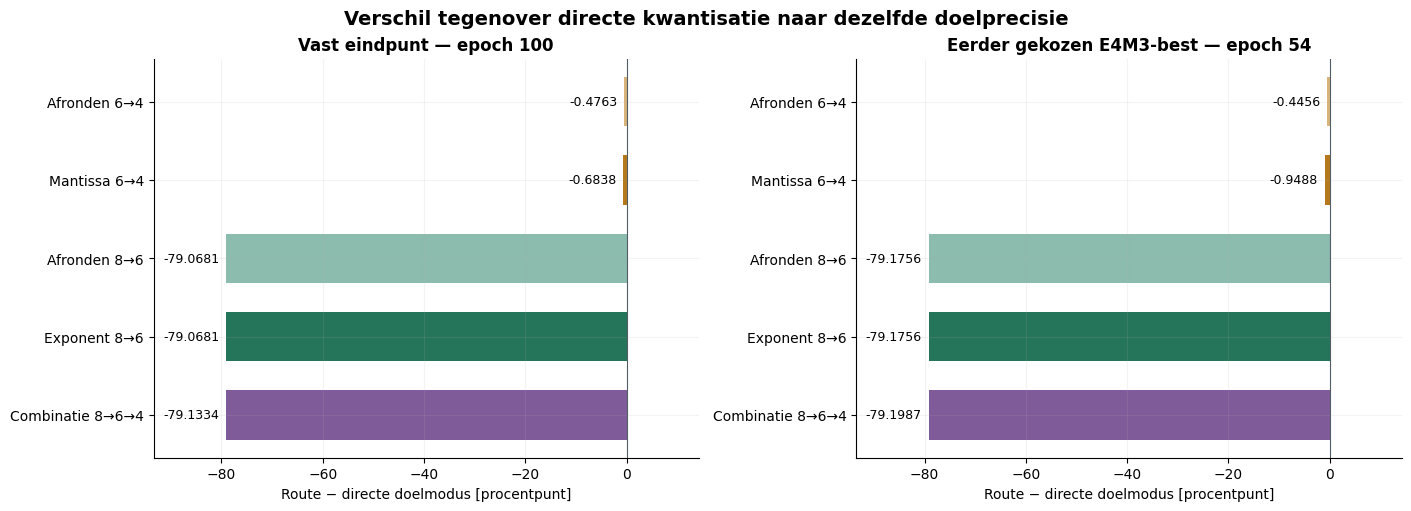

In [5]:
display(analysis.delta_table(run).style.format({"Delta accuracy [pp]": "{:+.4f}"}))
figures["accuracy_deltas"] = analysis.plot_accuracy_deltas(run)
plt.show()


## 4. Gepaarde voorspellingen: welke beelden winnen of verliezen?

Een klein netto verschil kan samengaan met veel gewijzigde voorspellingen. De tabel telt daarom fout→correct, correct→fout en fout→andere fout. Bij de directe routes helpt dit ook om de kleine accuracyverschillen tussen precisies te beschrijven. Uit twee checkpoints van één training volgt geen algemene superioriteits- of equivalentieclaim.

De richting is steeds `other_path − reference_path`. De notebook controleert de tellingen opnieuw vanuit de opgeslagen voorspellingen, zonder het model te laden.


,role,epoch,reference_path,other_path,accuracy_difference_pp,prediction_changes,wrong_to_correct,correct_to_wrong,wrong_to_other_wrong,net_correct_change
0,best_E4M3_test,54,direct8,direct6,+0.0768,124,58,38,28,20
1,best_E4M3_test,54,direct8,direct4,+0.0999,419,187,161,71,26
2,best_E4M3_test,54,direct6,direct4,+0.0230,401,169,163,69,6
3,best_E4M3_test,54,direct4,round64,-0.4456,584,183,299,102,-116
4,best_E4M3_test,54,direct4,mantissa64,-0.9488,992,285,532,175,-247
5,best_E4M3_test,54,round64,mantissa64,-0.5032,884,294,425,165,-131
6,best_E4M3_test,54,direct6,round86,-79.1756,21915,149,20760,1006,-20611
7,best_E4M3_test,54,direct6,exponent86,-79.1756,21915,149,20760,1006,-20611
8,best_E4M3_test,54,round86,exponent86,+0.0000,0,0,0,0,0
9,best_E4M3_test,54,direct4,combined864,-79.1987,21934,165,20782,987,-20617


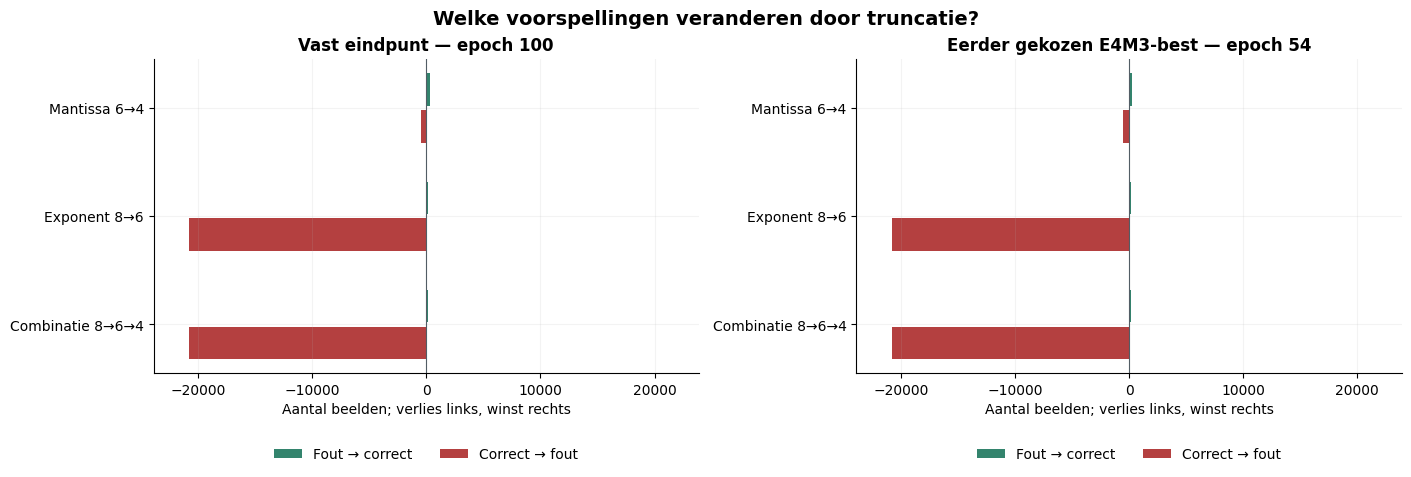

,Rol,Epoch,Testbeelden,NPZ-checksum,Acht routes,Gepaarde tellingen
0,last_epoch,100,26032,PASS,PASS,PASS
1,best_E4M3_test,54,26032,PASS,PASS,PASS


In [6]:
pair_columns = [c for c in ["role", "epoch", "reference_path", "other_path", "accuracy_difference_pp", "prediction_changes", "wrong_to_correct", "correct_to_wrong", "wrong_to_other_wrong", "net_correct_change"] if c in run.pairs]
display(run.pairs[pair_columns].style.format({"accuracy_difference_pp": "{:+.4f}"}))
figures["paired_changes"] = analysis.plot_paired_changes(run)
plt.show()
display(pd.DataFrame(run.output_checks))


## 5. Wat gebeurt er met de gewichten en de schaal?

Deze afwijkingen vergelijken **gedecodeerde gewichten tussen routes**. Zij zijn geen foutmaat tegenover de FP32-mastergewichten; die worden in deze proef niet ingelezen. Padding telt niet mee als echt gewicht.

De eerste figuur toont de MAE tegenover de directe doelmodus. De tweede toont de RMS-grootteverhouding tegenover diezelfde directe modus. Een verhouding ver van 1 maakt een verandering in gewichtsamplitude zichtbaar. De behouden E4M3-bronschaal kan bij een E2-doelformaat een groot effect hebben; er wordt hier niets gecompenseerd of opnieuw geleerd.


,role,epoch,layer,path,n_weights,mean_abs,rms,rms_ratio_to_direct,zero_count,local_subnormal_count,scale_exp_min,scale_exp_max,scale_anchor_path,scales_equal_source,nonzero_dropped_exponent_suffix_count,nonzero_dropped_mantissa_suffix_count
0,best_E4M3_test,54,layers.3,direct8,1728,0.063584,0.077114,1.000000,0,1,-12,-11,direct8,True,NaN,NaN
1,best_E4M3_test,54,layers.3,direct6,1728,0.063593,0.077135,1.000000,22,441,-6,-5,direct6,True,NaN,NaN
2,best_E4M3_test,54,layers.3,direct4,1728,0.062188,0.074913,1.000000,116,265,-6,-5,direct4,True,NaN,NaN
3,best_E4M3_test,54,layers.3,round64,1728,0.061469,0.074548,0.995126,162,187,-6,-5,direct6,True,NaN,NaN
4,best_E4M3_test,54,layers.3,mantissa64,1728,0.054873,0.068460,0.913852,233,230,-6,-5,direct6,True,NaN,1327.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
91,last_epoch,100,layers.20,round64,102400,0.026368,0.034791,0.985907,11543,13091,-9,-5,direct6,True,NaN,NaN
92,last_epoch,100,layers.20,mantissa64,102400,0.023020,0.031308,0.887196,15961,17157,-9,-5,direct6,True,NaN,77195.0
93,last_epoch,100,layers.20,round86,102400,0.001757,0.001919,0.053587,30,473,-15,-11,direct8,True,NaN,NaN
94,last_epoch,100,layers.20,exponent86,102400,0.001202,0.001347,0.037624,10,49,-15,-11,direct8,True,84700.0,NaN


,role,epoch,layer,reference_path,other_path,comparison,n_weights,code_differences,scale_code_differences,scale_bytes_equal,numeric_differences,mean_signed_difference,mae,rmse,max_abs_difference,reference_l2_norm,difference_l2_norm
0,best_E4M3_test,54,layers.3,direct4,round64,round64_minus_direct4,1728,211,0,True,211,-0.000059,0.002446,0.007454,0.031250,3.114092,0.309852
1,best_E4M3_test,54,layers.3,direct4,mantissa64,mantissa64_minus_direct4,1728,590,0,True,590,0.000190,0.007315,0.013321,0.031250,3.114092,0.553751
2,best_E4M3_test,54,layers.3,round64,mantissa64,mantissa64_minus_round64,1728,541,0,True,541,0.000249,0.006596,0.012558,0.031250,3.098915,0.522036
3,best_E4M3_test,54,layers.3,direct6,round86,round86_minus_direct6,1728,1724,64,False,1727,0.011888,0.060099,0.074209,0.136963,3.206445,3.084809
4,best_E4M3_test,54,layers.3,direct6,exponent86,exponent86_minus_direct6,1728,1436,64,False,1728,0.012013,0.061218,0.075050,0.138428,3.206445,3.119789
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
91,last_epoch,100,layers.20,direct6,round86,round86_minus_direct6,102400,101793,3200,False,102370,0.001827,0.025479,0.034336,0.136963,11.457359,10.987403
92,last_epoch,100,layers.20,direct6,exponent86,exponent86_minus_direct6,102400,90486,3200,False,102390,0.001823,0.026035,0.034723,0.138428,11.457359,11.111411
93,last_epoch,100,layers.20,round86,exponent86,exponent86_minus_round86,102400,93503,0,True,93503,-0.000004,0.000557,0.000723,0.002686,0.613962,0.231260
94,last_epoch,100,layers.20,direct4,combined864,combined864_minus_direct4,102400,92390,3200,False,102371,0.001717,0.025869,0.034345,0.123047,11.292316,10.990308


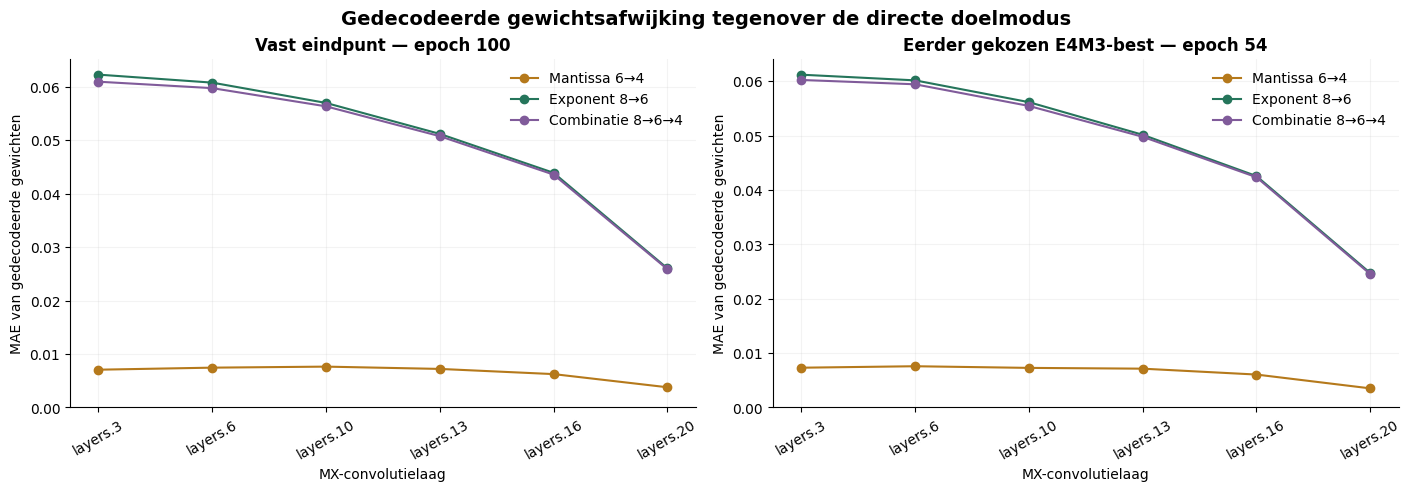

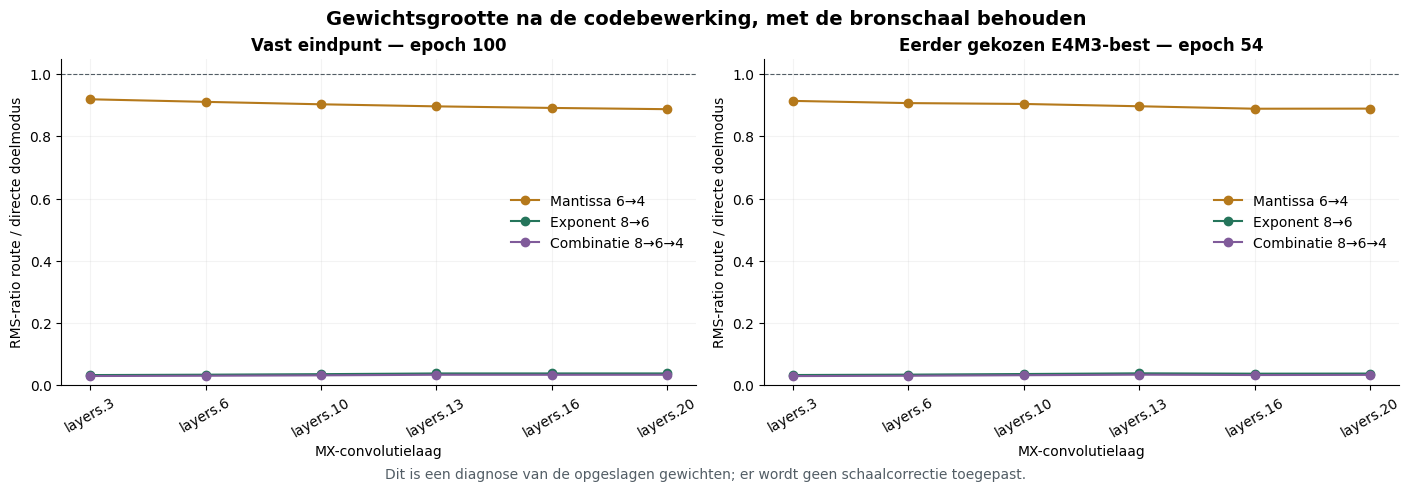

In [7]:
code_columns = [c for c in ["role", "epoch", "layer", "path", "n_weights", "mean_abs", "rms", "rms_ratio_to_direct", "zero_count", "local_subnormal_count", "scale_exp_min", "scale_exp_max", "scale_anchor_path", "scales_equal_source", "nonzero_dropped_exponent_suffix_count", "nonzero_dropped_mantissa_suffix_count"] if c in run.codes]
display(run.codes[code_columns])
display(run.weights)
figures["weight_differences"] = analysis.plot_weight_differences(run)
plt.show()
figures["weight_magnitudes"] = analysis.plot_weight_magnitudes(run)
plt.show()


## 6. Reproductie en uitvoeringscontroles

De opnieuw gemeten directe scores worden vergeleken met hun historische trainingsscores. Een verschil blijft zichtbaar en wordt niet gecorrigeerd om de oude score te reproduceren. De nieuwe, gelijktijdig gemeten vergelijkingen tussen routes zijn leidend voor deze post-hocproef.

De bestaande checkpointkeuze blijft vast. Het E4M3-bestcheckpoint was geselecteerd op de officiële testset; de score daarvan is geen onafhankelijke testschatting na selectie. Alle doel-BN-banken blijven bevroren. Dit is numerieke MX-emulatie met FP32-rekenbuffers, geen meting van native-MX-hardwarewinst.


In [8]:
display(run.reproduction)
display(analysis.audit_table(run))
display(Markdown(analysis.timing_markdown(run)))
if run.report.get("limitations"):
    display(Markdown("\n".join("- " + str(item) for item in run.report["limitations"])))


,role,epoch,path,historical_correct1,reevaluated_correct1,difference_correct1,accuracy_difference_pp,historical_ce,reevaluated_ce,correct1_matches_history
0,best_E4M3_test,54,direct8,24740,24740,0,0.0,0.214139,0.214138,True
1,best_E4M3_test,54,direct6,24760,24760,0,0.0,0.189812,0.189811,True
2,best_E4M3_test,54,direct4,24766,24766,0,0.0,0.182220,0.182220,True
3,last_epoch,100,direct8,24694,24694,0,0.0,0.236220,0.236221,True
4,last_epoch,100,direct6,24732,24732,0,0.0,0.200403,0.200406,True
5,last_epoch,100,direct4,24749,24749,0,0.0,0.186247,0.186246,True


,Rol,Epoch,Model/BN ongewijzigd,Geen gradients,Optimizerupdates,Zes FP32-masters afwezig,Checkpoint-SHA256
0,best_E4M3_test,54,True,True,0,True,ab2e05d40d82cccc971aa117cd08f5182174bc44b9f4b4...
1,last_epoch,100,True,True,0,True,987fdcda2a1d68f6faee9243d649cc0266eee37f5631fd...


**Gemeten evaluatiesessie: 0.29 minuten.** Deze tijd omvat de evaluatieroutes en administratie van deze proef. Zij is geen native-MX-snelheids- of energiebenchmark.

- The source was jointly trained for three direct MX modes, not for truncation.
- Every comparison to a direct target uses that same trained target BN bank; no recalibration.
- E4M3-best and epoch100 were already selected; no new selection or training occurs.
- One training seed; the two checkpoints are not independent repeats.
- All derived E8M0 scale bytes are copied unchanged from their respective MX source.
- E4M3-source scales differ from direct E2 scales; round86 is fixed-scale local rounding and can saturate.
- Exponent MSB truncation includes no exponent-bias correction or scale compensation.
- FP32 decoded buffers emulate MX; no native-kernel speed or energy claim.
- The six quantized FP32 masters are absent; FP32 exception layers and BN auxiliary state remain.
- A low truncation accuracy is an outcome, not a software FAIL; historical direct mismatches are reported.
- CUDA repeatability is not bit-exact under the original backend policy.

## 7. Figuren bewaren

Zet bovenaan `SAVE_FIGURES = True` en voer deze cel uit om PNG- en PDF-figuren in een **nieuwe** analysemap op te slaan. De ruwe rapporten, voorspellingen, exports en eerdere resultaten worden niet overschreven. Deze notebook slaat geen extra uitgevoerde notebookkopie op.


In [9]:
if SAVE_FIGURES:
    saved = analysis.save_figures(run, figures)
    print("Figuren opgeslagen in:", saved)
else:
    print("Figuuropslag staat uit; de bestaande bestanden zijn alleen gelezen.")


Figuren opgeslagen in: C:\Users\renzo\master-thesis-mx\mx_runs\mx_triple_posthoc_truncation_eval\20261023_173343_934141_evaluate\analysis_20261023_153641_801041
